# Sweep results
Reads `out/*/` (written by `run.py`). Re-run all cells after new runs finish.

In [18]:
import json, glob, os
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

rows, hists = [], {}
for d in sorted(glob.glob("out/*/")):
    name = os.path.basename(d.rstrip("/"))
    if not (os.path.exists(d+"config.json") and os.path.exists(d+"results.json")):
        continue                                   # still running or failed
    cfg = json.load(open(d+"config.json")); res = json.load(open(d+"results.json"))
    if cfg["model"] == "baselines":                # {baseline: {pair: metrics}}
        for bname, per_pair in res.items():
            for pair, m in per_pair.items():
                rows.append({"run": bname, "model": "baseline", "overrides": "", "min": None, "pair": pair, **m})
    else:                                          # {ALL/pair: metrics}
        hists[name] = json.load(open(d+"history.json"))
        for pair, m in res.items():
            rows.append({"run": name, "model": cfg["model"], "overrides": " ".join(cfg["overrides"]),
                         "min": cfg["minutes"], "pair": pair, **m})
df = pd.DataFrame(rows)
print(len(df.run.unique()), "runs loaded")

2 runs loaded


## Pooled (ALL), sorted by switch PR-AUC

In [19]:
cols = ["model","overrides","switch_PR_AUC","dur_macro_F1","switch_P","switch_R","joint_acc","val_ce_sw","val_ce_dur","min"]
a = df[df.pair=="ALL"].set_index("run")[cols]
a["score"] = 0.5*(a.switch_PR_AUC + a.dur_macro_F1)    # same as trainer.select_score
a.sort_values("score", ascending=False)

,model,overrides,switch_PR_AUC,dur_macro_F1,switch_P,switch_R,joint_acc,val_ce_sw,val_ce_dur,min,score
run,,,,,,,,,,,
yue_q4b_lora,qwen,"QWEN_NAME=""Qwen/Qwen3-4B-Base"" QWEN_BATCH_SIZE...",0.712,0.632,0.586,0.691,0.900,0.1902,0.8361,32.7,0.6720
yue_q06b,qwen,"QWEN_NAME=""Qwen/Qwen3-0.6B-Base"" QWEN_BATCH_SI...",0.684,0.621,0.600,0.645,0.902,0.1939,0.8533,22.8,0.6525


## Per pair

In [20]:
for metric in ["switch_PR_AUC", "dur_macro_F1", "joint_acc"]:
    print("\n==", metric, "==")
    display(df[df.pair!="ALL"].pivot(index="run", columns="pair", values=metric))


== switch_PR_AUC ==


pair,yue-en
run,
yue_q06b,0.684
yue_q4b_lora,0.712



== dur_macro_F1 ==


pair,yue-en
run,
yue_q06b,0.621
yue_q4b_lora,0.632



== joint_acc ==


pair,yue-en
run,
yue_q06b,0.902
yue_q4b_lora,0.900


## Training curves (val metrics per epoch, ALL)
Note `val_loss` is not comparable between XLM-R and Qwen3.

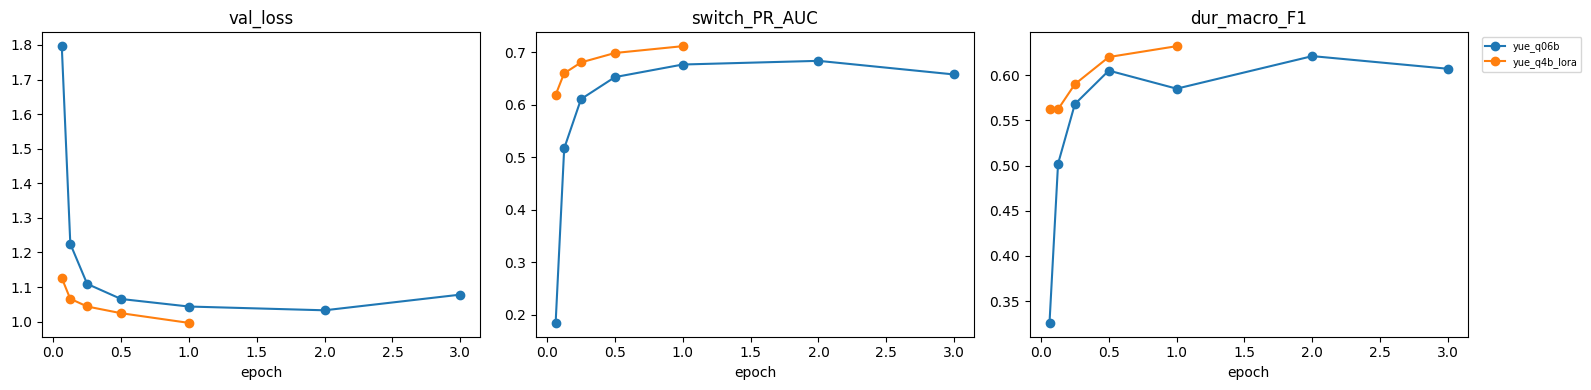

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
def unpack(h):
    # New: {"step","epoch","res"}; Old: one res dict/epoch
    if h and "res" in h[0]:
        return [e["epoch"] for e in h], [e["res"] for e in h]
    return list(range(1, len(h) + 1)), h

for name, h in hists.items():
    ep, rs = unpack(h)
    ax[0].plot(ep, [r["ALL"]["val_loss"] for r in rs], marker="o", label=name)
    ax[1].plot(ep, [r["ALL"]["switch_PR_AUC"] for r in rs], marker="o", label=name)
    ax[2].plot(ep, [r["ALL"]["dur_macro_F1"] for r in rs], marker="o", label=name)
for x, t in zip(ax, ["val_loss", "switch_PR_AUC", "dur_macro_F1"]):
    x.set_title(t); x.set_xlabel("epoch")
ax[2].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()